In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42

### Load Data & Stratified Train/Validation/Test Split:
Using `stratify` preserves the original class distribution across your training, validation, and test sets.

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

In [3]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2, stratify=y_temp, random_state=RANDOM_STATE)

print(f"Train shape: {X_train.shape} | Val shape: {X_val.shape} | Test shape: {X_test.shape}")

Train shape: (364, 30) | Val shape: (91, 30) | Test shape: (114, 30)


### Categorical Feature Handling (Optional):
Convert any categorical columns to pandas category dtype so XGBoost processes them natively without one-hot encoding.

In [4]:
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

for col in cat_cols:
    X_train[col] = X_train[col].astype("category")
    X_val[col] = X_val[col].astype("category")
    X_test[col] = X_test[col].astype("category")

### Train Baseline Model with Early Stopping:
For binary classification, `logloss` tracks probability calibration during training. If your dataset is imbalanced, set `scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()`

In [5]:
model = xgb.XGBClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    enable_categorical=True,
    early_stopping_rounds=50,
    eval_metric="logloss",
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False,
)

print(f"Best iteration: {model.best_iteration}")
print(f"Best validation LogLoss: {model.best_score:.4f}")

Best iteration: 111
Best validation LogLoss: 0.1305


### Evaluate on Test Set:

In [6]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"Test Accuracy: {acc:.4f}")
print(f"Test ROC-AUC:  {roc_auc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

Test Accuracy: 0.9386
Test ROC-AUC:  0.9934

Classification Report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



### Diagnostics — Learning Curve, Feature Importance & Confusion Matrix:

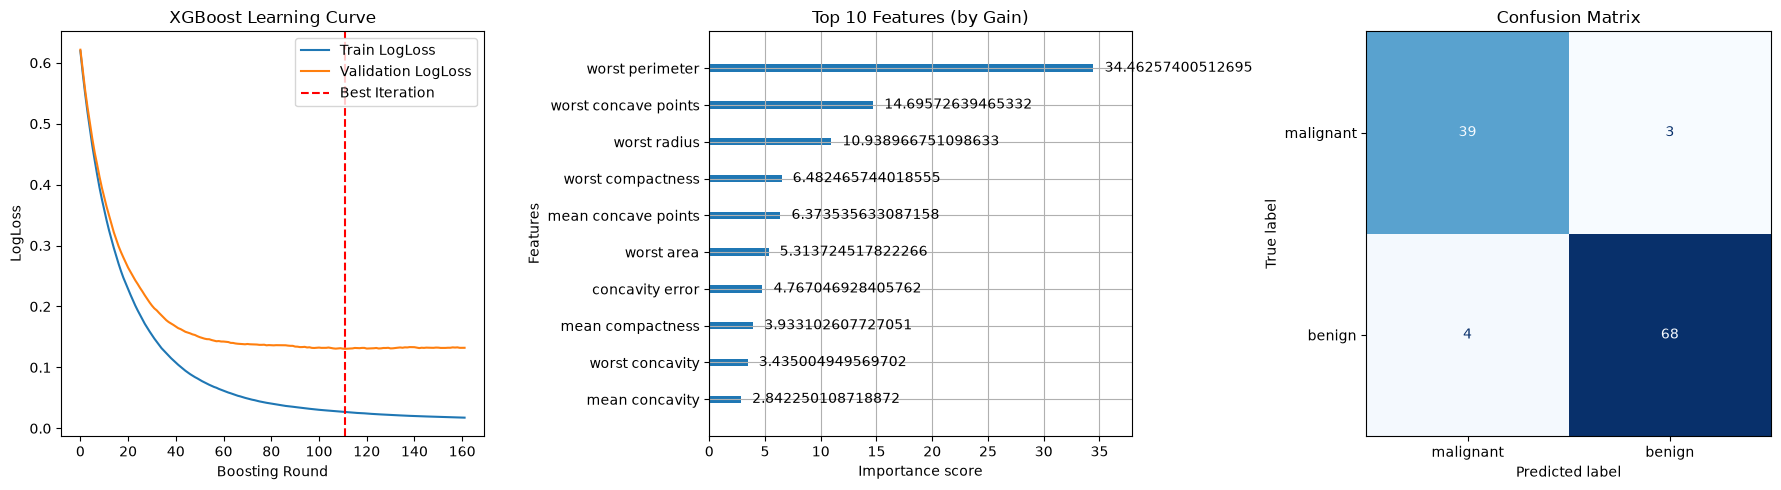

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

results = model.evals_result()
axes[0].plot(results["validation_0"]["logloss"], label="Train LogLoss")
axes[0].plot(results["validation_1"]["logloss"], label="Validation LogLoss")
axes[0].axvline(model.best_iteration, color="red", linestyle="--", label="Best Iteration")
axes[0].set_title("XGBoost Learning Curve")
axes[0].set_xlabel("Boosting Round")
axes[0].set_ylabel("LogLoss")
axes[0].legend()

xgb.plot_importance(
    model,
    ax=axes[1],
    importance_type="gain",
    max_num_features=10,
    title="Top 10 Features (by Gain)",
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=data.target_names,
    cmap="Blues",
    ax=axes[2],
    colorbar=False,
)
axes[2].set_title("Confusion Matrix")

plt.tight_layout()
plt.show()

### Hyperparameter Tuning with RandomizedSearchCV:

In [8]:
param_dist = {
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5, 10],
    "reg_alpha": [0, 0.1, 1.0],
    "reg_lambda": [1.0, 5.0, 10.0],
}

base_estimator = xgb.XGBClassifier(
    n_estimators=500,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    enable_categorical=True,
)

search = RandomizedSearchCV(
    estimator=base_estimator,
    param_distributions=param_dist,
    n_iter=20,
    scoring="roc_auc",
    cv=5,
    verbose=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

search.fit(X_train, y_train)

print("Best Parameters:", search.best_params_)
print(f"Best CV ROC-AUC: {search.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'subsample': 0.6, 'reg_lambda': 10.0, 'reg_alpha': 0.1, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
Best CV ROC-AUC: 0.9936
